# M4: 50% synthetic ablation experiments

Four conditions compare prompting composition and synthetic filtering over seeds 42, 123, and 2026. Every run uses 4,000 real and 4,000 synthetic training examples, balanced at 2,000 per class. The basic pool is too small for 4,000 basic examples, so *basic enriched* uses 400 basic (100 per class) and 3,600 advanced; *advanced only* uses 4,000 advanced. Filtered data comes from `full_filtered.csv`; unfiltered data comes from `full_unfiltered.csv`. All runs use DistilBERT, one epoch, learning rate 5e-5, weight decay 0.01, batch size 16, max length 128, and BF16 on CUDA. Validation is checked every 100 steps; the fixed original AG News test set is evaluated after training. No test results are used to choose checkpoints. The results describe this finite set of seeds and synthetic samples; the basic comparison changes only 10% of the synthetic half (5% of the entire training set).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'results' / 'ablations'
assert (OUT / 'runs.csv').exists(), 'Run python src/run_ablations.py first'

In [2]:
runs = pd.read_csv(OUT / 'runs.csv')
display(runs[['filtering','prompt_mix','seed','basic_count','advanced_count','validation_macro_f1','test_accuracy','test_macro_f1','test_recall_world','test_recall_sports','test_recall_business','test_recall_sci_tech','train_runtime_sec','peak_gpu_reserved_gb']].round(4))

,filtering,prompt_mix,seed,basic_count,advanced_count,validation_macro_f1,test_accuracy,test_macro_f1,test_recall_world,test_recall_sports,test_recall_business,test_recall_sci_tech,train_runtime_sec,peak_gpu_reserved_gb
0,unfiltered,advanced_only,42,0,4000,0.8978,0.8978,0.8980,0.8600,0.9747,0.8853,0.8711,43.7953,1.4492
1,unfiltered,advanced_only,123,0,4000,0.8961,0.8988,0.8988,0.8795,0.9821,0.8647,0.8689,43.6417,1.5312
2,unfiltered,advanced_only,2026,0,4000,0.8971,0.9034,0.9034,0.8789,0.9784,0.8816,0.8747,62.7001,1.4629
3,unfiltered,basic_enriched,42,400,3600,0.8939,0.8970,0.8971,0.8658,0.9747,0.8811,0.8663,45.3197,1.5254
4,unfiltered,basic_enriched,123,400,3600,0.8962,0.8962,0.8962,0.8821,0.9795,0.8658,0.8574,44.1518,1.4629
5,unfiltered,basic_enriched,2026,400,3600,0.8987,0.8996,0.8997,0.8826,0.9726,0.8795,0.8637,44.6455,1.5273
6,filtered,advanced_only,42,0,4000,0.8958,0.8978,0.8980,0.8653,0.9747,0.8847,0.8663,45.5443,1.4512
7,filtered,advanced_only,123,0,4000,0.8880,0.8970,0.8969,0.8747,0.9826,0.8632,0.8674,45.6421,1.4570
8,filtered,advanced_only,2026,0,4000,0.9026,0.9012,0.9013,0.8763,0.9779,0.8926,0.8579,45.4293,1.4570
9,filtered,basic_enriched,42,400,3600,0.8942,0.8972,0.8974,0.8626,0.9779,0.8863,0.8621,45.1286,1.4551


In [3]:
comparison = pd.read_csv(OUT / 'comparison.csv')
display(comparison.round(4))

,filtering,prompt_mix,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,test_recall_world_mean,test_recall_world_std,test_recall_sports_mean,test_recall_sports_std,...,test_recall_sci_tech_mean,test_recall_sci_tech_std,validation_accuracy_mean,validation_accuracy_std,validation_macro_f1_mean,validation_macro_f1_std,train_runtime_sec_mean,train_runtime_sec_std,peak_gpu_reserved_gb_mean,peak_gpu_reserved_gb_std
0,filtered,advanced_only,0.8986,0.0022,0.8987,0.0023,0.8721,0.0060,0.9784,0.0040,...,0.8639,0.0052,0.8953,0.0073,0.8955,0.0073,45.5386,0.1065,1.4551,0.0034
1,filtered,basic_enriched,0.8976,0.0036,0.8976,0.0037,0.8758,0.0115,0.9781,0.0018,...,0.8625,0.0100,0.8938,0.0028,0.8940,0.0028,44.7325,0.6285,1.4518,0.0074
2,unfiltered,advanced_only,0.9000,0.0030,0.9001,0.0029,0.8728,0.0111,0.9784,0.0037,...,0.8716,0.0029,0.8968,0.0008,0.8970,0.0009,50.0457,10.9593,1.4811,0.0439
3,unfiltered,basic_enriched,0.8976,0.0018,0.8977,0.0018,0.8768,0.0096,0.9756,0.0035,...,0.8625,0.0046,0.8960,0.0025,0.8963,0.0024,44.7057,0.5863,1.5052,0.0367


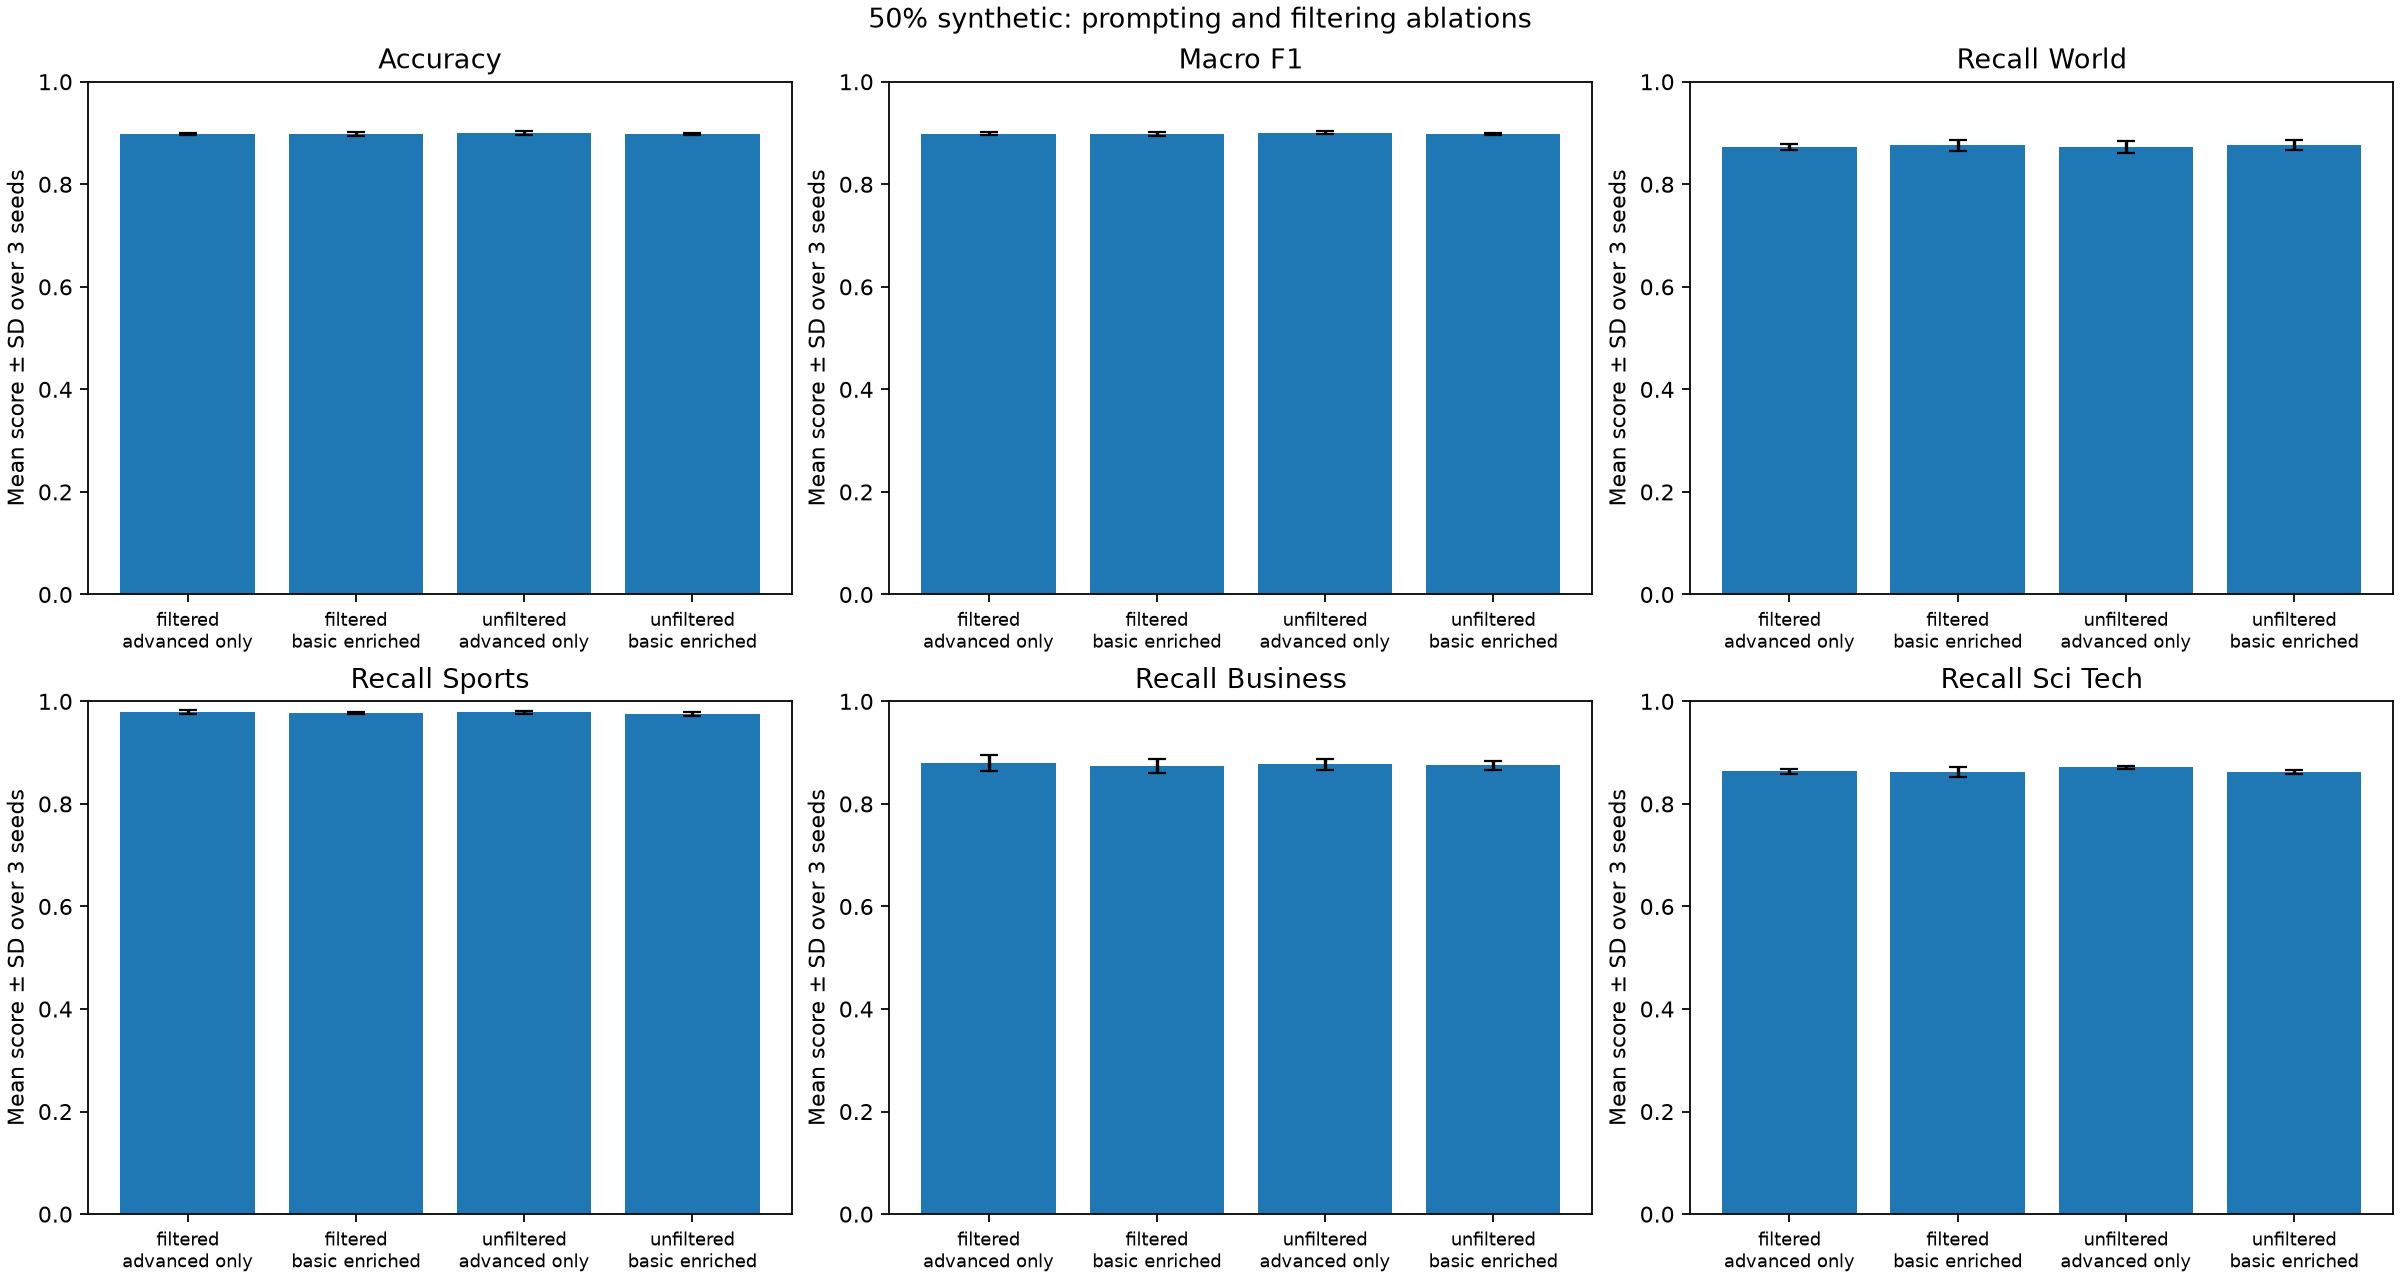

In [4]:
display(Image(filename=str(OUT / 'comparison.png')))

In [5]:
paired = json.loads((OUT / 'paired_differences.json').read_text(encoding='utf-8'))
display(pd.DataFrame(paired))

,comparison,filtering,mean_macro_f1_difference,seed_differences,prompt_mix
0,basic_enriched minus advanced_only,unfiltered,-0.002384,"{'42': -0.000827137476744233, '123': -0.002594...",NaN
1,basic_enriched minus advanced_only,filtered,-0.001100,"{'42': -0.0005482366146672968, '123': -0.00283...",NaN
2,filtered minus unfiltered,NaN,-0.001354,"{'42': 5.2407735332549166e-06, '123': -0.00192...",advanced_only
3,filtered minus unfiltered,NaN,-0.000069,"{'42': 0.0002841416356101911, '123': -0.002161...",basic_enriched


In [6]:
best = comparison.loc[comparison['test_macro_f1_mean'].idxmax()]
print(f"Highest mean test macro F1: {best['filtering']} / {best['prompt_mix']} = {best['test_macro_f1_mean']:.4f} ± {best['test_macro_f1_std']:.4f}")
print('Small sample: three training seeds per condition. Treat differences as descriptive, not definitive.')

Highest mean test macro F1: unfiltered / advanced_only = 0.9001 ± 0.0029
Small sample: three training seeds per condition. Treat differences as descriptive, not definitive.
